# Базові моделі на результатах пілота
Цей notebook **навчає** частотний контроль, логістичну регресію та випадковий ліс. Працює на CPU з готовим `dataset.json`: GPU, архіви сцен, кадри, карти й ваги локалізатора не потрібні. Jev не викликається.
Попередня перевірка — почергово на відкладених просторових групах (у поточному пілоті — чотири сцени). Усі повтори кадру залишаються разом. Це розвідувальний аналіз 8 кадрів, а не остаточна незалежна перевірка. Калібрування на цьому етапі не підбираємо.
Перед початком скопіюйте **оновлений пакет correction_prediction цілком** у Drive. Збережений пілот повторно запускати не потрібно.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import sys, json
REPO_ROOT = Path('/content/drive/MyDrive/PhD/proj')
EXPERIMENT = REPO_ROOT/'scripts/correction_prediction'
DATASET = EXPERIMENT/'results/pilot-v2-cublas/dataset.json'
BASELINE_OUTPUT = EXPERIMENT/'results/pilot-baselines-v1'
INSTALL_DEPENDENCIES = False  # True лише якщо потрібне встановлення CPU-залежностей
RUN_BASELINES = True
required = ['pilot_baselines.py', 'models.py', 'reporting.py', 'environment.py', 'requirements-baselines-colab.txt']
missing = [name for name in required if not (EXPERIMENT/name).is_file()]
assert not missing, f'Оновіть весь пакет у Drive; відсутні: {missing}'
assert DATASET.is_file(), f'Потрібен готовий файл з успішного пілота: {DATASET}'
sys.path.insert(0, str(REPO_ROOT))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## CPU-середовище
Якщо потрібні бібліотеки вже встановлені після пілота, залиште INSTALL_DEPENDENCIES=False. За потреби встановлення виставте True. Якщо комірка вимагає Restart session, перезапустіть Python, поверніть False і виконайте notebook зверху. Перевірка відбувається до навчання. Torch та моделі локалізації тут не встановлюються.

In [2]:
import subprocess, importlib.util
# Завантаження stdlib-only перевірки до імпорту наукових бібліотек пакета.
spec = importlib.util.spec_from_file_location('baseline_environment', EXPERIMENT/'environment.py')
environment = importlib.util.module_from_spec(spec)
spec.loader.exec_module(environment)
_BASELINE_ENVIRONMENT_READY = False
loaded_before = environment.loaded_snapshot()
if INSTALL_DEPENDENCIES:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-r', str(EXPERIMENT/'requirements-baselines-colab.txt')], check=True)
    environment.require_clean_kernel(loaded_before)
environment.require_clean_kernel()
environment.verify_scipy_imports()
import numpy, scipy, sklearn, pandas, matplotlib, cv2, shapely, pyproj
_BASELINE_ENVIRONMENT_READY = True
print('CPU-середовище готове. NumPy:', numpy.__version__, 'SciPy:', scipy.__version__, 'sklearn:', sklearn.__version__)

CPU-середовище готове. NumPy: 2.1.3 SciPy: 1.14.1 sklearn: 1.6.1


In [3]:
from scripts.correction_prediction.dataset import load_dataset
from scripts.correction_prediction.contracts import CLASS_NAMES
from collections import Counter
import pandas as pd
data = load_dataset(DATASET)
assert data['provenance']['stage'] == 'pilot', 'Цей notebook призначений для пілотних даних'
rows = data['rows']
print('Спроб:', len(rows), 'Унікальних кадрів:', len({(r['scene_id'], r['sample_id']) for r in rows}))
print('Технічні помилки:', sum(r['label']['technical_error'] for r in rows))
print('Непідтримувані ознаки:', sum(r['features'] is None for r in rows))
table = pd.DataFrame([{'scene': r['scene_id'], 'outcome': r['label'].get('class_name', 'technical_error')} for r in rows])
display(pd.crosstab(table['scene'], table['outcome']).reindex(columns=CLASS_NAMES, fill_value=0))
print('Моделі не отримають GT, кадри камери або фактичні похибки як ознаки.')

Спроб: 288 Унікальних кадрів: 8
Технічні помилки: 0
Непідтримувані ознаки: 0


outcome,reject,harm_large,harm,harm_small,neutral,gain_small,gain,gain_large
scene,,,,,,,,
Scene_05,13,0,0,0,1,13,11,34
Scene_08,11,0,1,3,1,3,12,41
Scene_11,0,0,0,0,1,15,2,54
Scene_21,3,0,0,0,0,5,22,42


Моделі не отримають GT, кадри камери або фактичні похибки як ознаки.


## Навчання та перевірка
У кожному проході одна ціла просторова група відкладена, інші використовуються для навчання. Для поточного пілота це 216 навчальних спроб на 6 кадрах та 72 перевірочні спроби на 2 кадрах. Налаштування фіксовані; пошуку гіперпараметрів і температурного калібрування немає.
П'ять кандидатів: constant, logistic_geometry, logistic_map, forest_geometry, forest_map. Після групової перевірки всі п'ять додатково навчаються на повному пілоті й зберігаються як exploratory_models. Їхні прогнози на навчальних даних не подаються як оцінка узагальнення.
Каталог результатів має бути новим. Якщо він уже існує, перегляньте його нижче або змініть назву; вхідні дані й старі результати не перезаписуються.

In [4]:
if RUN_BASELINES:
    assert _BASELINE_ENVIRONMENT_READY, 'Спочатку виконайте перевірку середовища'
    from scripts.correction_prediction.pilot_baselines import run_pilot_baselines
    summary = run_pilot_baselines(DATASET, BASELINE_OUTPUT)
    print('Моделі й звіти збережено:', BASELINE_OUTPUT)
else:
    print('Навчання пропущено; нижче можна прочитати наявні результати.')

fold-01: held out Scene_05; train=216, held=72
fold-02: held out Scene_08; train=216, held=72
fold-03: held out Scene_11; train=216, held=72
fold-04: held out Scene_21; train=216, held=72
Refitting all five fixed candidates on the full pilot; research use only.
Моделі й звіти збережено: /content/drive/MyDrive/PhD/proj/scripts/correction_prediction/results/pilot-baselines-v1


,OOF log loss,OOF Brier,accepted RPS,harm Brier,scene macro log loss
model,,,,,
constant,1.292092,0.619445,0.069751,0.014294,1.292092
forest_geometry,1.115195,0.423137,0.036261,0.014628,1.115195
forest_map,1.165768,0.439476,0.038363,0.014416,1.165768
logistic_geometry,1.538491,0.526172,0.058758,0.058801,1.538491
logistic_map,1.917126,0.600167,0.057257,0.014327,1.917126


Перевірка окремо за кожною відкладеною сценою:


,,attempts,log loss,Brier,predicted harm,observed harm
scene,model,,,,,
Scene_05,constant,72,1.455192,0.727829,3.125000e-02,0.000000
Scene_08,constant,72,1.443197,0.640559,1.339286e-02,0.055556
Scene_11,constant,72,1.068056,0.502662,3.125000e-02,0.000000
Scene_21,constant,72,1.201926,0.606731,3.125000e-02,0.000000
Scene_05,forest_geometry,72,0.780954,0.465165,2.552253e-02,0.000000
Scene_08,forest_geometry,72,2.325566,0.516200,3.000000e-12,0.055556
Scene_11,forest_geometry,72,0.577179,0.267001,1.768416e-02,0.000000
Scene_21,forest_geometry,72,0.777081,0.444183,1.170230e-02,0.000000
Scene_05,forest_map,72,0.830284,0.471892,2.773687e-02,0.000000


LIMITATION: Exploratory pilot only: dependent repetitions and very few scenes.
LIMITATION: Spatial independence between different scene IDs has not been established by this diagnostic.
LIMITATION: Probabilities are uncalibrated. No model was selected on an independent test.
LIMITATION: The all-data refits were not evaluated on new data and are not ready for planner use.
LIMITATION: Harm evidence: 4 worsening attempts in 2 distinct frames; dependent repetitions do not establish rare-event reliability.
LIMITATION: Classes absent from the entire usable pilot: harm_large
validation_passed: False final_test_evaluated: False


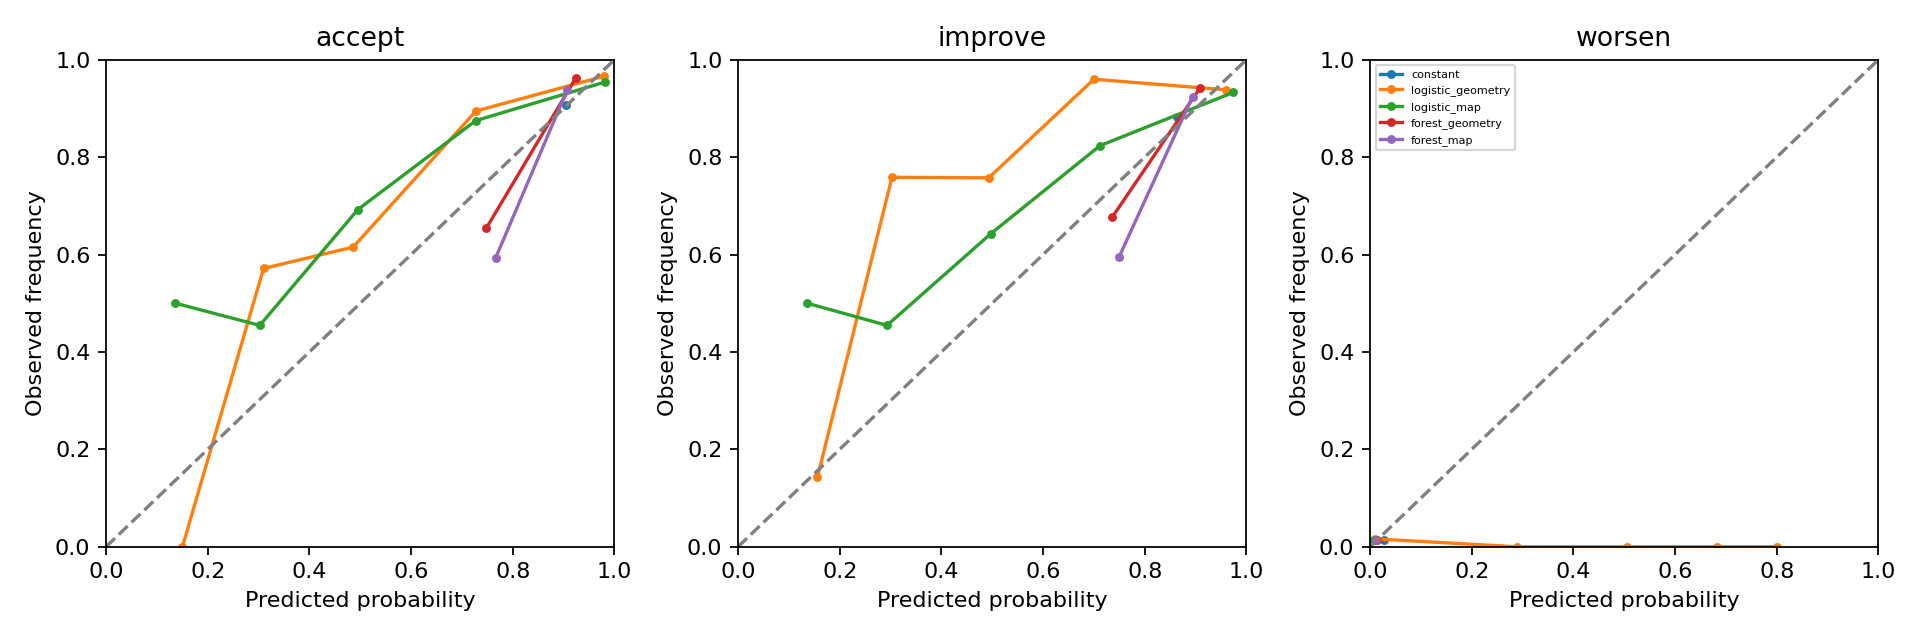

"# Exploratory pilot baselines: held-out spatial groups\n\nNo model selected. No calibration or independent final test.\n\n| Candidate | Log loss | Multiclass Brier | Accepted conditional RPS |\n|---|---:|---:|---:|\n| constant | 1.292092 | 0.619445 | 0.069751410068258 |\n| logistic_geometry | 1.538491 | 0.526172 | 0.05875768779873002 |\n| logistic_map | 1.917126 | 0.600167 | 0.057257101728097386 |\n| forest_geometry | 1.115195 | 0.423137 | 0.03626088198921553 |\n| forest_map | 1.165768 | 0.439476 | 0.038362872492144456 |\n\nFinal test evaluated: False. Validation passed: false.\n\nResearch only. Technical failures and unsupported queries are separately reported.\nFrame repetitions are dependent. These scores do not certify route arrival or safety.\nConditional RPS evaluates accepted outcomes only; log loss covers all eight classes.\nRare/missing classes and few independent territories limit claims.\n\nOOF checks on a small, already inspected pilot. All-data refits are research-only.\n"

- Exploratory pilot only: dependent repetitions and very few scenes.
- Spatial independence between different scene IDs has not been established by this diagnostic.
- Probabilities are uncalibrated. No model was selected on an independent test.
- The all-data refits were not evaluated on new data and are not ready for planner use.
- Harm evidence: 4 worsening attempts in 2 distinct frames; dependent repetitions do not establish rare-event reliability.
- Classes absent from the entire usable pilot: harm_large


In [5]:
if (BASELINE_OUTPUT/'summary.json').is_file():
    summary = json.loads((BASELINE_OUTPUT/'summary.json').read_text())
    comparison, per_scene = [], []
    for name, scores in summary['evaluations'].items():
        s = scores['overall']
        comparison.append({'model': name, 'OOF log loss': s['log_loss'], 'OOF Brier': s['brier_score'], 'accepted RPS': s['conditional_accepted_rps'], 'harm Brier': s['events']['worsen']['brier_score'], 'scene macro log loss': scores['scene_macro_log_loss']})
        for scene, values in scores['by_scene'].items():
            per_scene.append({'model': name, 'scene': scene, 'attempts': values['sample_count'], 'log loss': values['log_loss'], 'Brier': values['brier_score'], 'predicted harm': values['events']['worsen']['predicted'], 'observed harm': values['events']['worsen']['observed']})
    display(pd.DataFrame(comparison).set_index('model'))
    print('Перевірка окремо за кожною відкладеною сценою:')
    display(pd.DataFrame(per_scene).set_index(['scene', 'model']))
    for warning in summary['warnings']:
        print('LIMITATION:', warning)
    print('validation_passed:', summary['validation_passed'], 'final_test_evaluated:', summary['final_test_evaluated'])
    from IPython.display import Image, Markdown
    display(Image(filename=str(BASELINE_OUTPUT/'calibration.png')))
    display(Markdown((BASELINE_OUTPUT/'report.md').read_text()))
else:
    print('Результатів навчання ще немає.')

## Що зберегти
Увесь каталог BASELINE_OUTPUT: summary.json, report.md, calibration.png, folds.json, oof_predictions.json, bin_sensitivity.json, fold_models/ та exploratory_models/.
Графік калібрування показує якість **сирих** OOF-імовірностей; він не означає, що калібрування було навчене. Погіршень у завершеному пілоті лише чотири, великих погіршень немає — надійність прогнозування рідкісної шкоди цими даними не доведена.
Для розбору результатів скопіюйте каталог у локальну папку results цього експерименту. Остаточна перевірка, калібрування, розширення даних та Jev залишаються окремими етапами.